# Охват рекламы в Яндекс Лавке


**Автор:** Хабибуллин Азамат  
**Группа:** 13

На семинаре заполните разделы 1–3 и начните работу с данными. Дома завершите расчёты, выводы и ограничения. Добавляйте ячейки по мере необходимости.

[ТЗ](assignment.md) · [Описание данных](README.md)

Распакуйте архив целиком и сохраняйте ноутбук рядом с тремя CSV и папкой `images`.

## 1. Бизнес-контекст

Зачем бизнесу нужны эти данные?

Рекламная команда Яндекс Лавки планирует продажи рекламных размещений до конца 2026 года. Чтобы оценивать рекламный инвентарь и предлагать размещения рекламодателям, команде необходимо понимать потенциальный среднедневной охват каждого рекламного места.
Оценка охвата позволит сравнить рекламные позиции между собой и понять, сколько уникальных пользователей в среднем за день потенциально может увидеть рекламу в каждом из выбранных мест.

## 2. Исследовательский вопрос

Зафиксируйте вопрос, на который вы хотите ответить в рамках этого исследования?
#### Какой среднедневной охват может обеспечить каждое из выбранных рекламных мест в каждом месяце до конца года, если реклама доступна для показа всем пользователям без ограничений таргетинга?

Какой среднедневной охват в уникальных пользователях потенциально могут обеспечить четыре рекламных места в товарной ленте и рекламный баннер на стартовом экране поиска в октябре, ноябре и декабре 2026 года?

## 3. Методология

Сначала опишите, каким способом вы ответите на исследовательский вопрос (краткое описание общей логики). Затем уточните детали: какие данные вы будете использовать, и как будете их преобразовывать/агрегировать. Описание должно быть достаточно подробным, чтобы другой аналитик мог воспроизвести ваш подход.


Для оценки будущего охвата используется поведение пользователей за сентябрь 2026 года. Поскольку в данных отсутствуют прямые события показа рекламных баннеров, для каждого рекламного места используется наблюдаемое событие-прокси, которое соответствует потенциальному просмотру баннера.
Для каждого дня сентября рассчитывается число уникальных пользователей, потенциально увидевших рекламное место. Затем этот охват делится на дневной DAU, чтобы получить долю активных пользователей, достигающих соответствующего места. Среднее значение этой доли за сентябрь используется как оценка вероятности того, что активный пользователь увидит рекламное место.
Прогноз среднедневного охвата на октябрь, ноябрь и декабрь рассчитывается как произведение этой средней доли на прогнозный DAU соответствующего месяца.
$$
ForecastReach_{placement,month} = AvgReachRate_{placement} \times ForecastDAU_{month}
$$


Для рекламных мест в товарной ленте прямые показы баннеров в данных отсутствуют. Однако расположение баннеров в интерфейсе фиксировано, и рядом с каждым рекламным местом находится товарная карточка с известными координатами.
Предполагается, что пользователь, увидевший соседнюю товарную карточку, одновременно потенциально видит и рекламный баннер. Поэтому охват соответствующей товарной карточки используется как proxy охвата рекламного места.
$$
Reach_{banner,d} = Nunique(users\,who\,saw\,proxy\,card\,on\,day\,d)
$$

Баннер на странице поиска показывается на стартовом экране раздела поиска. После ввода поискового запроса пользователь переходит на экран результатов, где баннер отсутствует.
Поэтому proxy-событием для показа поискового баннера считается открытие стартового экрана поиска до ввода запроса. Пользователь учитывается в дневном охвате один раз независимо от количества открытий поиска в течение дня.
$$
Reach_{search,d} = Nunique(users\,who\,opened\,initial\,search\,screen)
$$

Расчёт ведётся на дневном уровне, поскольку целевая метрика — среднедневной охват. Пользователь, активный в несколько дней сентября, должен учитываться отдельно в каждом дне, а не один раз за весь месяц.

**Дневная доля охвата**
Для любого размещения:
$$
ReachRate_{placement,d} = \frac{Reach_{placement,d}}{DAU_d}
$$

А потом:
$$
AvgReachRate_{placement} = mean(ReachRate_{placement,d})
$$

## 4. Подготовка данных и реализация расчётов

### 4.1. Загрузка и знакомство с данными

Загрузите три таблицы и изучите их структуру и содержимое.

In [1]:
import pandas as pd

product_impressions = pd.read_csv('product_impressions.csv')
dau_forecast = pd.read_csv('dau_forecast.csv')
navigation_events = pd.read_csv('navigation_events.csv')

In [2]:
product_impressions.head()

,user_id,timestamp,section,product_id,row_number,column
0,u04000,2026-09-01 07:00:24,feed,p0775,"1,0",left
1,u04000,2026-09-01 07:00:24,feed,p0842,"1,0",right
2,u04000,2026-09-01 07:00:28,feed,p1782,"2,0",left
3,u04000,2026-09-01 07:00:28,feed,p1788,"2,0",right
4,u02703,2026-09-01 07:00:31,search,p0723,"1,0",left


In [3]:
product_impressions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 455882 entries, 0 to 455881
Data columns (total 6 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   user_id     455882 non-null  object
 1   timestamp   455882 non-null  object
 2   section     455882 non-null  object
 3   product_id  455882 non-null  object
 4   row_number  455882 non-null  object
 5   column      455882 non-null  object
dtypes: object(6)
memory usage: 20.9+ MB


In [4]:
dau_forecast.head()

,month,avg_dau_plan,avg_dau_actual
0,2026-01,"820,00","811,35"
1,2026-02,"840,00","853,18"
2,2026-03,"875,00","864,52"
3,2026-04,"900,00","913,70"
4,2026-05,"930,00","921,16"


In [5]:
dau_forecast.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   month           12 non-null     object
 1   avg_dau_plan    12 non-null     object
 2   avg_dau_actual  12 non-null     object
dtypes: object(3)
memory usage: 420.0+ bytes


In [6]:
navigation_events.head()

,user_id,timestamp,event_type,section
0,u02703,01.09.2026 07:00:19,app_open,NaN
1,u04000,01.09.2026 07:00:19,app_open,NaN
2,u04000,01.09.2026 07:00:22,section_open,feed
3,u02703,01.09.2026 07:00:29,section_open,search
4,u02703,01.09.2026 07:00:50,section_open,search


In [7]:
navigation_events.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 91302 entries, 0 to 91301
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     91302 non-null  object
 1   timestamp   91302 non-null  object
 2   event_type  91302 non-null  object
 3   section     54161 non-null  object
dtypes: object(4)
memory usage: 2.8+ MB


В файле navigation_events  есть пропуски в столбце section.

### 4.2. Подготовка данных

Проверьте, готовы ли данные к расчётам. Выполните необходимые преобразования и объясните принятые решения.

In [8]:
product_impressions['timestamp'] = pd.to_datetime(product_impressions['timestamp'])
navigation_events['timestamp'] = pd.to_datetime(navigation_events['timestamp'], dayfirst=True)

In [9]:
product_impressions['date'] = product_impressions['timestamp'].dt.date
navigation_events['date'] = navigation_events['timestamp'].dt.date

In [10]:
product_impressions['row_number'] = (product_impressions['row_number'].str.replace(',', '.', regex = False).astype(float).astype(int))

In [11]:


for col in ['avg_dau_plan', 'avg_dau_actual']:
    dau_forecast[col] = (
        dau_forecast[col]
        .astype(str)
        .str.replace(r'[^\d.,\-]', '', regex=True)  # убираем всё, кроме цифр, точки, запятой, минуса
        .str.replace(',', '.', regex=False)          # меняем запятую на точку
        .replace(['', '-', '.', 'nan'], None)        # пустые/мусорные -> NaN
        .astype(float)
    )

In [12]:
dau_forecast.head()

,month,avg_dau_plan,avg_dau_actual
0,2026-01,820.0,811.35
1,2026-02,840.0,853.18
2,2026-03,875.0,864.52
3,2026-04,900.0,913.70
4,2026-05,930.0,921.16


In [13]:
dau_forecast['month'] = pd.to_datetime(
    dau_forecast['month'],
    format='%Y-%m'
)

In [14]:
product_impressions.info()
navigation_events.info()
dau_forecast.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 455882 entries, 0 to 455881
Data columns (total 7 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   user_id     455882 non-null  object        
 1   timestamp   455882 non-null  datetime64[ns]
 2   section     455882 non-null  object        
 3   product_id  455882 non-null  object        
 4   row_number  455882 non-null  int32         
 5   column      455882 non-null  object        
 6   date        455882 non-null  object        
dtypes: datetime64[ns](1), int32(1), object(5)
memory usage: 22.6+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 91302 entries, 0 to 91301
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   user_id     91302 non-null  object        
 1   timestamp   91302 non-null  datetime64[ns]
 2   event_type  91302 non-null  object        
 3   section     54161 non-null

In [15]:
product_impressions.section.unique()

array(['feed', 'search', ' feed ', 'FEED', 'SEARCH', 'catalog', 'CATALOG',
       ' catalog ', ' search '], dtype=object)

In [16]:
product_impressions.column.unique()

array(['left', 'right'], dtype=object)

In [17]:
navigation_events.section.unique()

array([nan, 'feed', 'search', 'catalog', ' search ', 'FEED', ' feed ',
       ' catalog ', 'CATALOG', 'SEARCH'], dtype=object)

In [18]:
navigation_events.event_type.unique()

array(['app_open', 'section_open'], dtype=object)

In [19]:
product_impressions['section'] = (
    product_impressions['section']
    .str.strip()
    .str.lower()
)

navigation_events['section'] = (
    navigation_events['section']
    .str.strip()
    .str.lower()
)


Изменил типы данных: столбцы с датами перевел в тип данных даты, столбцы в которых были числа, перевел в int. Далее нужно будет работать с датами, выделять месяцы, дни. Также нужно будет считать суммы, поэтому столбцы с числами переведены в числовой тип.

### 4.3. Расчёты

Реализуйте описанную методологию. Сопровождайте расчёты пояснениями и проверьте полученные результаты.

#### Считаем для каталога

In [52]:
#считаем DAU по каждому дню
daily_dau = (
    navigation_events
    .query("event_type == 'app_open'")
    .groupby('date', as_index=False)
    .agg(dau=('user_id', 'nunique'))
)

daily_dau.head()

,date,dau
0,2026-09-01,962
1,2026-09-02,997
2,2026-09-03,1008
3,2026-09-04,938
4,2026-09-05,1145


In [53]:
#задаём proxy-карточки четырёх рекламных мест
banner_map = pd.DataFrame({
    'placement': [
        'feed_banner_1',
        'feed_banner_2',
        'feed_banner_3',
        'feed_banner_4'
    ],
    'row_number': [3, 6, 12, 15],
    'column': ['left', 'right', 'right', 'left']
})
banner_map.head()

,placement,row_number,column
0,feed_banner_1,3,left
1,feed_banner_2,6,right
2,feed_banner_3,12,right
3,feed_banner_4,15,left


In [54]:
#Отбираю только товарную ленту
feed_impressions = product_impressions.query("section == 'feed'").copy()
feed_impressions.head()

,user_id,timestamp,section,product_id,row_number,column,date
0,u04000,2026-09-01 07:00:24,feed,p0775,1,left,2026-09-01
1,u04000,2026-09-01 07:00:24,feed,p0842,1,right,2026-09-01
2,u04000,2026-09-01 07:00:28,feed,p1782,2,left,2026-09-01
3,u04000,2026-09-01 07:00:28,feed,p1788,2,right,2026-09-01
6,u04000,2026-09-01 07:00:32,feed,p0109,3,left,2026-09-01


In [55]:
#Оставляем только нужные карточки
catalog_proxy = feed_impressions.merge(banner_map, on=['row_number', 'column'], how='inner')
catalog_proxy.head()

,user_id,timestamp,section,product_id,row_number,column,date,placement
0,u04000,2026-09-01 07:00:32,feed,p0109,3,left,2026-09-01,feed_banner_1
1,u03492,2026-09-01 07:01:49,feed,p0652,3,left,2026-09-01,feed_banner_1
2,u03492,2026-09-01 07:02:06,feed,p1654,3,left,2026-09-01,feed_banner_1
3,u03492,2026-09-01 07:02:19,feed,p0430,6,right,2026-09-01,feed_banner_2
4,u03399,2026-09-01 07:02:49,feed,p1277,3,left,2026-09-01,feed_banner_1


In [56]:
#Найдем число уникальных пользователей по каждому дню и каждому рекламному месту
catalog_daily_reach = (catalog_proxy.groupby(['date', 'placement'], as_index=False).agg(unique_users = ('user_id', 'nunique')))
catalog_daily_reach.head()

,date,placement,unique_users
0,2026-09-01,feed_banner_1,452
1,2026-09-01,feed_banner_2,280
2,2026-09-01,feed_banner_3,121
3,2026-09-01,feed_banner_4,82
4,2026-09-02,feed_banner_1,477


In [57]:
catalog_daily_reach = catalog_daily_reach.merge(daily_dau, on='date', how='left')
catalog_daily_reach.head()
#получим таблицу, показывающую сколько уникальных пользователей посмотрело баннер в течение дня

,date,placement,unique_users,dau
0,2026-09-01,feed_banner_1,452,962
1,2026-09-01,feed_banner_2,280,962
2,2026-09-01,feed_banner_3,121,962
3,2026-09-01,feed_banner_4,82,962
4,2026-09-02,feed_banner_1,477,997


In [58]:
#Считаем долю
catalog_daily_reach['reach_rate'] = (catalog_daily_reach['unique_users'] / catalog_daily_reach['dau'])


In [60]:
#Считаем среднюю дневную долю за сентябрь
catalog_avg_rates = (catalog_daily_reach.groupby('placement', as_index=False).agg(avg_daily_reach=('unique_users', 'mean'), avg_reach_rate=('reach_rate', 'mean')))

catalog_avg_rates

,placement,avg_daily_reach,avg_reach_rate
0,feed_banner_1,498.607143,0.489610
1,feed_banner_2,313.071429,0.307066
2,feed_banner_3,143.857143,0.140685
3,feed_banner_4,103.464286,0.100988


#### Теперь считаем для страницы поиска

In [65]:
search_open = navigation_events.query("event_type == 'section_open' and section == 'search'").copy()
search_open.head()

,user_id,timestamp,event_type,section,date
3,u02703,2026-09-01 07:00:29,section_open,search,2026-09-01
4,u02703,2026-09-01 07:00:50,section_open,search,2026-09-01
5,u04000,2026-09-01 07:00:51,section_open,search,2026-09-01
11,u01241,2026-09-01 07:01:58,section_open,search,2026-09-01
21,u00551,2026-09-01 07:03:27,section_open,search,2026-09-01


In [68]:
search_daily_reach = ( search_open.groupby('date', as_index= False).agg(unique_users = ('user_id', 'nunique')) )
search_daily_reach.head()

,date,unique_users
0,2026-09-01,373
1,2026-09-02,369
2,2026-09-03,393
3,2026-09-04,351
4,2026-09-05,419


In [69]:
search_daily_reach = (search_daily_reach.merge(daily_dau, on = 'date', how = 'left'))
search_daily_reach.head()

,date,unique_users,dau
0,2026-09-01,373,962
1,2026-09-02,369,997
2,2026-09-03,393,1008
3,2026-09-04,351,938
4,2026-09-05,419,1145


In [70]:
search_daily_reach['reach_rate'] = (search_daily_reach['unique_users']/ search_daily_reach['dau'])

In [72]:
search_avg_rate = search_daily_reach['reach_rate'].mean()

print(f'{search_avg_rate:.2%}')
#около 37% дневной аудитории открывает стартовый экран поиска

37.25%


#### Объединим все баннера 

In [73]:
search_avg_rates = pd.DataFrame({'placement': ['search_banner'],'avg_reach_rate': [search_avg_rate]})
placement_rates = pd.concat([catalog_avg_rates[['placement', 'avg_reach_rate']],search_avg_rates],ignore_index=True)

placement_rates

,placement,avg_reach_rate
0,feed_banner_1,0.489610
1,feed_banner_2,0.307066
2,feed_banner_3,0.140685
3,feed_banner_4,0.100988
4,search_banner,0.372460


In [76]:
#берём плановый DAU октября–декабря
forecast_q4 = (
    dau_forecast[
        dau_forecast['month'].dt.month.isin([10, 11, 12])
    ]
    [['month', 'avg_dau_plan']]
    .copy()
)
forecast_q4

,month,avg_dau_plan
9,2026-10-01,1080.0
10,2026-11-01,1160.0
11,2026-12-01,1320.0


In [78]:
forecast_result = forecast_q4.merge(placement_rates,how='cross')
forecast_result.head()

,month,avg_dau_plan,placement,avg_reach_rate
0,2026-10-01,1080.0,feed_banner_1,0.489610
1,2026-10-01,1080.0,feed_banner_2,0.307066
2,2026-10-01,1080.0,feed_banner_3,0.140685
3,2026-10-01,1080.0,feed_banner_4,0.100988
4,2026-10-01,1080.0,search_banner,0.372460


In [80]:
#СЧитаем прогноз
forecast_result['avg_daily_reach'] = (forecast_result['avg_dau_plan'] * forecast_result['avg_reach_rate']).round().astype(int)
forecast_result.head()

,month,avg_dau_plan,placement,avg_reach_rate,avg_daily_reach
0,2026-10-01,1080.0,feed_banner_1,0.489610,529
1,2026-10-01,1080.0,feed_banner_2,0.307066,332
2,2026-10-01,1080.0,feed_banner_3,0.140685,152
3,2026-10-01,1080.0,feed_banner_4,0.100988,109
4,2026-10-01,1080.0,search_banner,0.372460,402


In [89]:
final_result = (forecast_result.pivot(index='placement',columns='month',values='avg_daily_reach'))

final_result.columns = final_result.columns.strftime('%Y-%m')

final_result

month,2026-10,2026-11,2026-12
placement,,,
feed_banner_1,529,568,646
feed_banner_2,332,356,405
feed_banner_3,152,163,186
feed_banner_4,109,117,133
search_banner,402,432,492


##### Средняя доля дневной аудитории, достигающей рекламных мест в товарной ленте, закономерно снижается по мере увеличения глубины расположения: примерно с 49% для первого рекламного места до 10% для четвёртого. Стартовый экран поиска в среднем открывают около 37% DAU. Полученные доли используются как коэффициенты для прогнозирования среднедневного охвата в октябре–декабре.

##### Получаем, что наибольший охват среди баннеров в каталоге получает самый первый, т.е. самый высокий. Вполне рациональный результат, потому что не все пользователи долистывают до конца каталога. Так же относительно высокий охват получает баннер около поисковой строки.

*Пояснения и результаты проверок.*

### 4.4. Результаты

Представьте оценку среднедневного охвата каждого выбранного места по месяцам — с октября по декабрь. Выберите понятный способ представления результатов и укажите единицы измерения.

In [90]:
placement_names = {
    'feed_banner_1': 'Баннер 1 в ленте',
    'feed_banner_2': 'Баннер 2 в ленте',
    'feed_banner_3': 'Баннер 3 в ленте',
    'feed_banner_4': 'Баннер 4 в ленте',
    'search_banner': 'Баннер в поиске'
}
forecast_result['placement_name'] = (
    forecast_result['placement']
    .map(placement_names)
)

In [91]:
final_result = (
    forecast_result
    .pivot(
        index='placement_name',
        columns='month',
        values='avg_daily_reach'
    )
)
final_result.columns = [
    'Октябрь',
    'Ноябрь',
    'Декабрь'
]
placement_order = [
    'Баннер 1 в ленте',
    'Баннер 2 в ленте',
    'Баннер 3 в ленте',
    'Баннер 4 в ленте',
    'Баннер в поиске'
]

final_result = final_result.reindex(placement_order)

#### Среднее количество уникальных пользователей в день 

In [93]:
final_result

,Октябрь,Ноябрь,Декабрь
placement_name,,,
Баннер 1 в ленте,529,568,646
Баннер 2 в ленте,332,356,405
Баннер 3 в ленте,152,163,186
Баннер 4 в ленте,109,117,133
Баннер в поиске,402,432,492


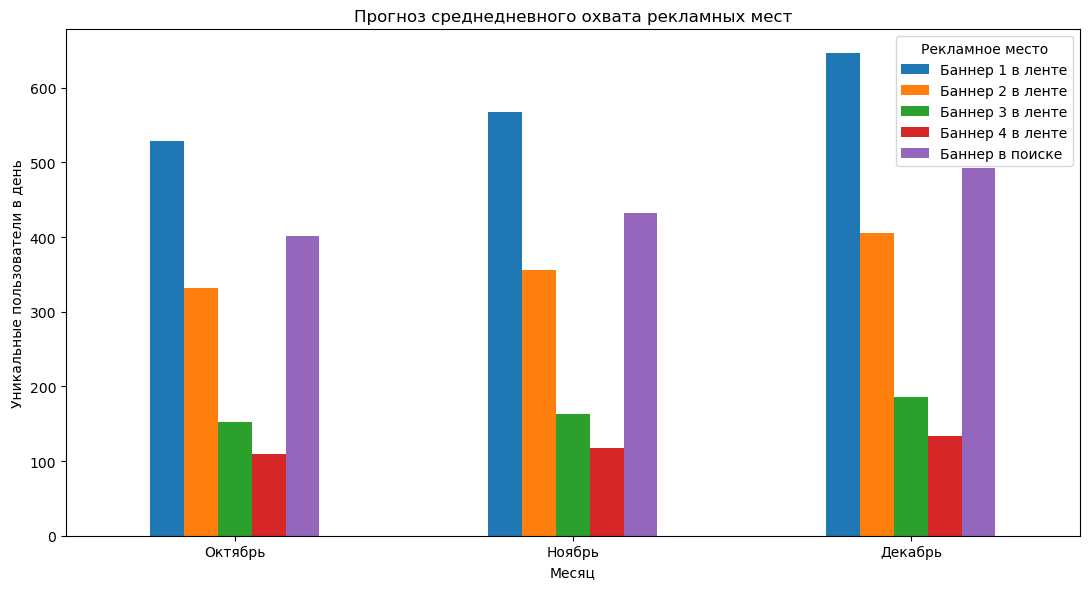

In [94]:
import matplotlib.pyplot as plt

final_result.T.plot(
    kind='bar',
    figsize=(11, 6)
)

plt.title('Прогноз среднедневного охвата рекламных мест')
plt.xlabel('Месяц')
plt.ylabel('Уникальные пользователи в день')
plt.xticks(rotation=0)
plt.legend(title='Рекламное место')
plt.tight_layout()

plt.show()

#### Среди рекламных мест в товарной ленте наибольший потенциальный охват имеет первое размещение. По мере увеличения глубины ленты охват снижается, поскольку до более глубоких позиций доходит меньшая доля активных пользователей.
#### Баннер на стартовом экране поиска обеспечивает меньший охват, чем первое размещение в ленте, но больший, чем более глубокие рекламные позиции.
#### Прогнозный среднедневной охват увеличивается от октября к декабрю вслед за ростом планового DAU. В модели доля пользователей, достигающих каждого рекламного места, остаётся постоянной.

## 5. Вывод

Ответьте на исследовательский вопрос, опираясь на результаты. Сформулируйте ответ так, чтобы рекламная команда могла использовать его при планировании.



По результатам расчётов потенциальный среднедневной охват рекламных мест заметно различается в зависимости от их расположения в интерфейсе.

Среди рекламных мест в товарной ленте наибольший охват имеет первый баннер. В октябре его потенциально увидят в среднем около **529 пользователей в день**, в ноябре — **568**, а в декабре — **646**.

По мере увеличения глубины расположения баннера охват снижается:

- второй баннер: **332** пользователя в день в октябре, **356** в ноябре и **405** в декабре;
- третий баннер: **152** пользователя в день в октябре, **163** в ноябре и **186** в декабре;
- четвёртый баннер: **109** пользователей в день в октябре, **117** в ноябре и **133** в декабре.

Баннер на стартовом экране поиска имеет второй по величине потенциальный охват среди рассматриваемых рекламных мест: около **402 пользователей в день** в октябре, **432** в ноябре и **492** в декабре.

Таким образом, наиболее охватным рекламным местом является первый баннер в товарной ленте. Баннер в поиске уступает ему по охвату, но значительно превосходит более глубокие позиции в ленте.

Рост среднедневного охвата с октября по декабрь связан с увеличением прогнозного DAU. В расчёте предполагается, что доля пользователей, достигающих каждого рекламного места, остаётся на уровне, наблюдаемом в сентябре.



## 6. Ограничения

Что ограничивает применимость ваших оценок? Объясните, как это влияет на интерпретацию и использование результатов.



При интерпретации полученных результатов необходимо учитывать следующие ограничения:

1. **Отсутствие прямых данных о показах рекламных баннеров.** В исследовании использовались косвенные показатели (proxy). Для баннеров в товарной ленте охват оценивался по показам соседних товарных карточек, а для баннера в поиске — по событиям открытия раздела поиска. Такой подход позволяет приблизительно оценить потенциальный охват, но не гарантирует полного совпадения с фактическим количеством пользователей, увидевших рекламу.

2. **Допущение об одновременной видимости баннера и соседней карточки.** Предполагается, что пользователь, увидевший товарную карточку рядом с рекламным местом, также увидел сам баннер. Однако фактическая видимость может зависеть от размера экрана, особенностей прокрутки и отображения элементов интерфейса.

3. **Ограниченный период наблюдения.** Для анализа использовались данные за 1–28 сентября 2026 года. Поведение пользователей в этот период может отличаться от поведения в октябре–декабре из-за сезонности, праздничных периодов или изменения пользовательских привычек.

4. **Неизменность пользовательского поведения в прогнозе.** При расчёте будущего охвата предполагается, что доля активных пользователей, достигающих каждого рекламного места, остаётся на уровне сентября. Если пользователи начнут чаще пользоваться поиском или глубже просматривать товарную ленту, фактический охват может отличаться от прогноза.

5. **Зависимость от точности прогноза DAU.** Для расчётов использовались плановые значения среднедневной активной аудитории на октябрь, ноябрь и декабрь. Если фактический DAU окажется выше или ниже планового, реальный охват рекламных мест также изменится.

Таким образом, **полученные значения следует рассматривать как оценки потенциального среднедневного охвата**, а не как гарантированное количество пользователей, которые увидят рекламные баннеры. Несмотря на ограничения, результаты позволяют сравнить рекламные места по доступной аудитории и использовать эти оценки при планировании рекламных размещений.